# Evaluating out-of-distribution detector

In [1]:
import itertools

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from matplotlib import rcParams
from matplotlib.patches import Patch
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score

from tcr_pmhc_predicted_structures.models import PAEAggregator

In [2]:
NUM_SAMPLES = 25
SAMPLE_SIZE = 500
SEED = 123
SIGNIFICANCE_LEVEL = 0.05

In [3]:
sequences = pd.read_csv('../data/interim/sequences_sample_1500_af_training.csv', index_col='id')

In [4]:
sequences['type'] = sequences['label'].map(lambda label: 'Binding' if label else 'Non-Binding')

In [5]:
confidence_scores_1500 = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_1500.csv')
confidence_scores_1500['name'] = confidence_scores_1500['name'].astype(str)

confidence_scores_af_training = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_af_training.csv')

confidence_scores = pd.concat([confidence_scores_1500, confidence_scores_af_training]).reset_index(drop=True)

confidence_scores = confidence_scores.merge(sequences, how='left', left_on='name', right_index=True)

In [6]:
with h5py.File('../data/processed/af3_af3_tcrmodel2_pae.h5', 'r') as fh:
    paes = fh['pae'][:]

    names = np.array([name.decode() for name in fh['id'][:]])
    seeds = fh['seed'][:]
    samples = fh['sample'][:]

    folds = fh['fold'][:]

In [7]:
pca = PCA(n_components=2).fit_transform(paes)

In [8]:
pca_df = pd.DataFrame(
    {
        'name': names,
        'seed': seeds,
        'sample': samples,
        'pc1': pca[:, 0],
        'pc2': pca[:, 1],
    }
)
pca_df = pca_df.merge(sequences, how='left', left_on='name', right_index=True)

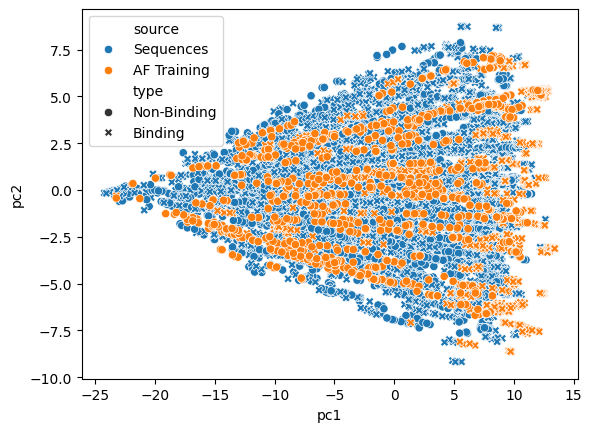

In [9]:
sns.scatterplot(pca_df, x='pc1', y='pc2', hue='source', style='type')
plt.show()

## Original

ROC-AUC: 0.6678921616161616


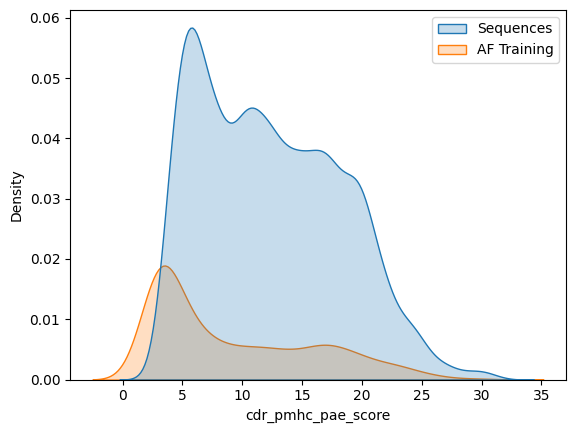

In [10]:
ax = sns.kdeplot(confidence_scores, x='cdr_pmhc_pae_score', fill=True, hue='source')

legend = ax.get_legend()
legend.set_title(None)

print('ROC-AUC:', roc_auc_score(confidence_scores['source'], confidence_scores['cdr_pmhc_pae_score']))
plt.show()

In [11]:
rng = np.random.default_rng(seed=SEED)

original_roc_auc_scores = []
for _ in range(NUM_SAMPLES):
    sample = confidence_scores.sample(SAMPLE_SIZE, random_state=rng)
    original_roc_auc_scores.append(1 - roc_auc_score(sample['label'], sample['cdr_pmhc_pae_score']))

## Untrained Aggregator Model

In [12]:
model = PAEAggregator(3120)
model.eval()

predictions = model(torch.Tensor(paes)).cpu().detach().numpy()

untrained_predictions = pd.DataFrame(
    {'name': names, 'seed': seeds, 'sample': samples, 'untrained_prediction': predictions}
)

In [13]:
confidence_scores = confidence_scores.merge(untrained_predictions, how='left', on=['name', 'seed', 'sample'])

ROC-AUC: 0.66791301010101


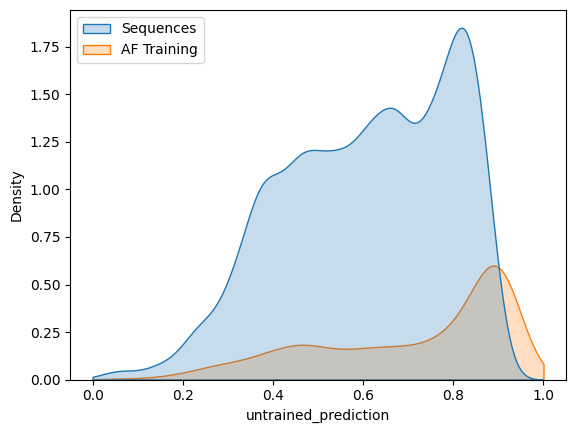

In [14]:
ax = sns.kdeplot(confidence_scores, x='untrained_prediction', hue='source', fill=True, clip=(0, 1))

legend = ax.get_legend()
legend.set_title(None)

print('ROC-AUC:', 1 - roc_auc_score(confidence_scores['source'], confidence_scores['untrained_prediction']))

In [15]:
rng = np.random.default_rng(seed=SEED)

untrained_roc_auc_scores = []
for _ in range(NUM_SAMPLES):
    sample = confidence_scores.sample(SAMPLE_SIZE, random_state=rng)
    untrained_roc_auc_scores.append(roc_auc_score(sample['label'], sample['untrained_prediction']))

## Trained Aggregator

In [16]:
trained_predictions = pd.DataFrame()
weights = []
for fold in sorted(np.unique(folds)):
    model = PAEAggregator(3120)
    model.load_state_dict(
        torch.load(
            f'../models/PAEAggregator_af3_af3_tcrmodel2_source_detection/model_{fold}.pt',
            weights_only=True,
            map_location=torch.device('cpu'),
        ),
    )
    model.eval()

    fold_mask = folds == fold

    predictions = model(torch.Tensor(paes[fold_mask])).cpu().detach().numpy()

    trained_predictions = pd.concat(
        [
            trained_predictions,
            pd.DataFrame(
                {
                    'name': names[fold_mask],
                    'seed': seeds[fold_mask],
                    'sample': samples[fold_mask],
                    'trained_prediction': predictions,
                }
            ),
        ]
    )

    weights.append(model.weights.cpu().detach().numpy())

weights = np.array(weights)

In [17]:
confidence_scores = confidence_scores.merge(trained_predictions, how='left', on=['name', 'seed', 'sample'])

ROC-AUC: 0.6080063434343435


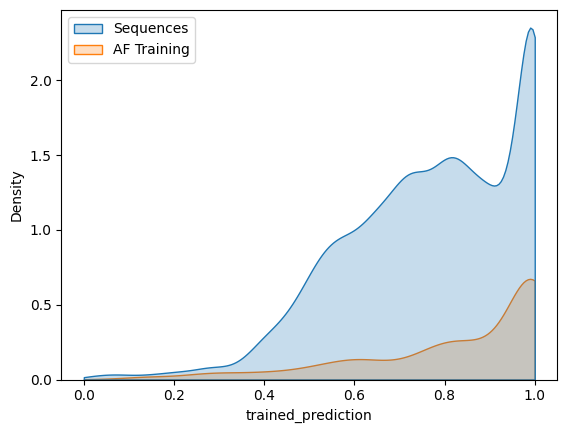

In [18]:
ax = sns.kdeplot(confidence_scores, x='trained_prediction', hue='source', fill=True, clip=(0, 1))

legend = ax.get_legend()
legend.set_title(None)

print('ROC-AUC:', 1 - roc_auc_score(confidence_scores['source'], confidence_scores['trained_prediction']))
plt.show()

In [19]:
rng = np.random.default_rng(seed=SEED)

trained_roc_auc_scores = []
for _ in range(NUM_SAMPLES):
    sample = confidence_scores.sample(SAMPLE_SIZE, random_state=rng)
    trained_roc_auc_scores.append(roc_auc_score(sample['label'], sample['trained_prediction']))

### Investigating learned weights

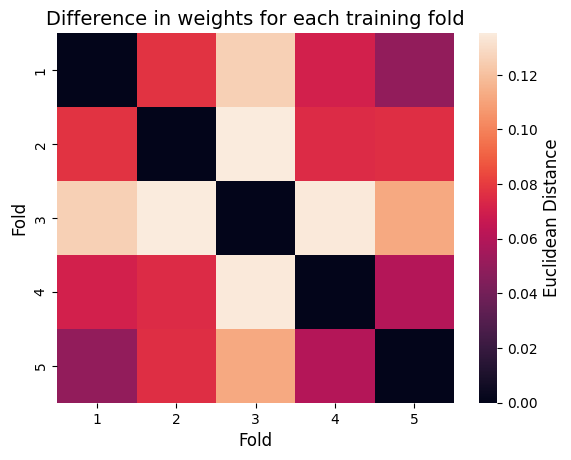

In [20]:
folds = np.unique(folds)
num_folds = len(folds)
differences = np.zeros((num_folds, num_folds))

for i, j in itertools.combinations(range(num_folds), 2):
    differences[i][j] = np.sqrt(np.sum((weights[i] - weights[j]) ** 2))

differences = np.maximum(differences, differences.T)

ax = sns.heatmap(differences, xticklabels=folds, yticklabels=folds)

ax.set_title('Difference in weights for each training fold', fontsize=14)
ax.collections[0].colorbar.set_label('Euclidean Distance', fontsize=12)
ax.set_xlabel('Fold', fontsize=12)
ax.set_ylabel('Fold', fontsize=12)

plt.show()

In [21]:
cdr_1a_length = 8
cdr_2a_length = 8
cdr_3a_length = 24
cdr_1b_length = 8
cdr_2b_length = 8
cdr_3b_length = 24

mhc_pseudo_length = 27
peptide_length = 12

column_labels = np.repeat(
    np.array(['cdr_1a', 'cdr_2a', 'cdr_3a', 'cdr_1b', 'cdr_2b', 'cdr_3b']),
    np.array([cdr_1a_length, cdr_2a_length, cdr_3a_length, cdr_1b_length, cdr_2b_length, cdr_3b_length]),
)

row_labels = np.repeat(np.array(['mhc_pseudo', 'peptide']), np.array([mhc_pseudo_length, peptide_length]))

rows, cols = np.meshgrid(row_labels, column_labels)
labels = np.char.add(cols, '-')
labels = np.char.add(labels, rows)

labels = labels.flatten()

In [22]:
colour_cycle = rcParams['axes.prop_cycle'].by_key()['color']
label_to_colour = {label: colour_cycle[i % len(colour_cycle)] for i, label in enumerate(np.unique(labels))}

colours = np.vectorize(label_to_colour.get)(labels)

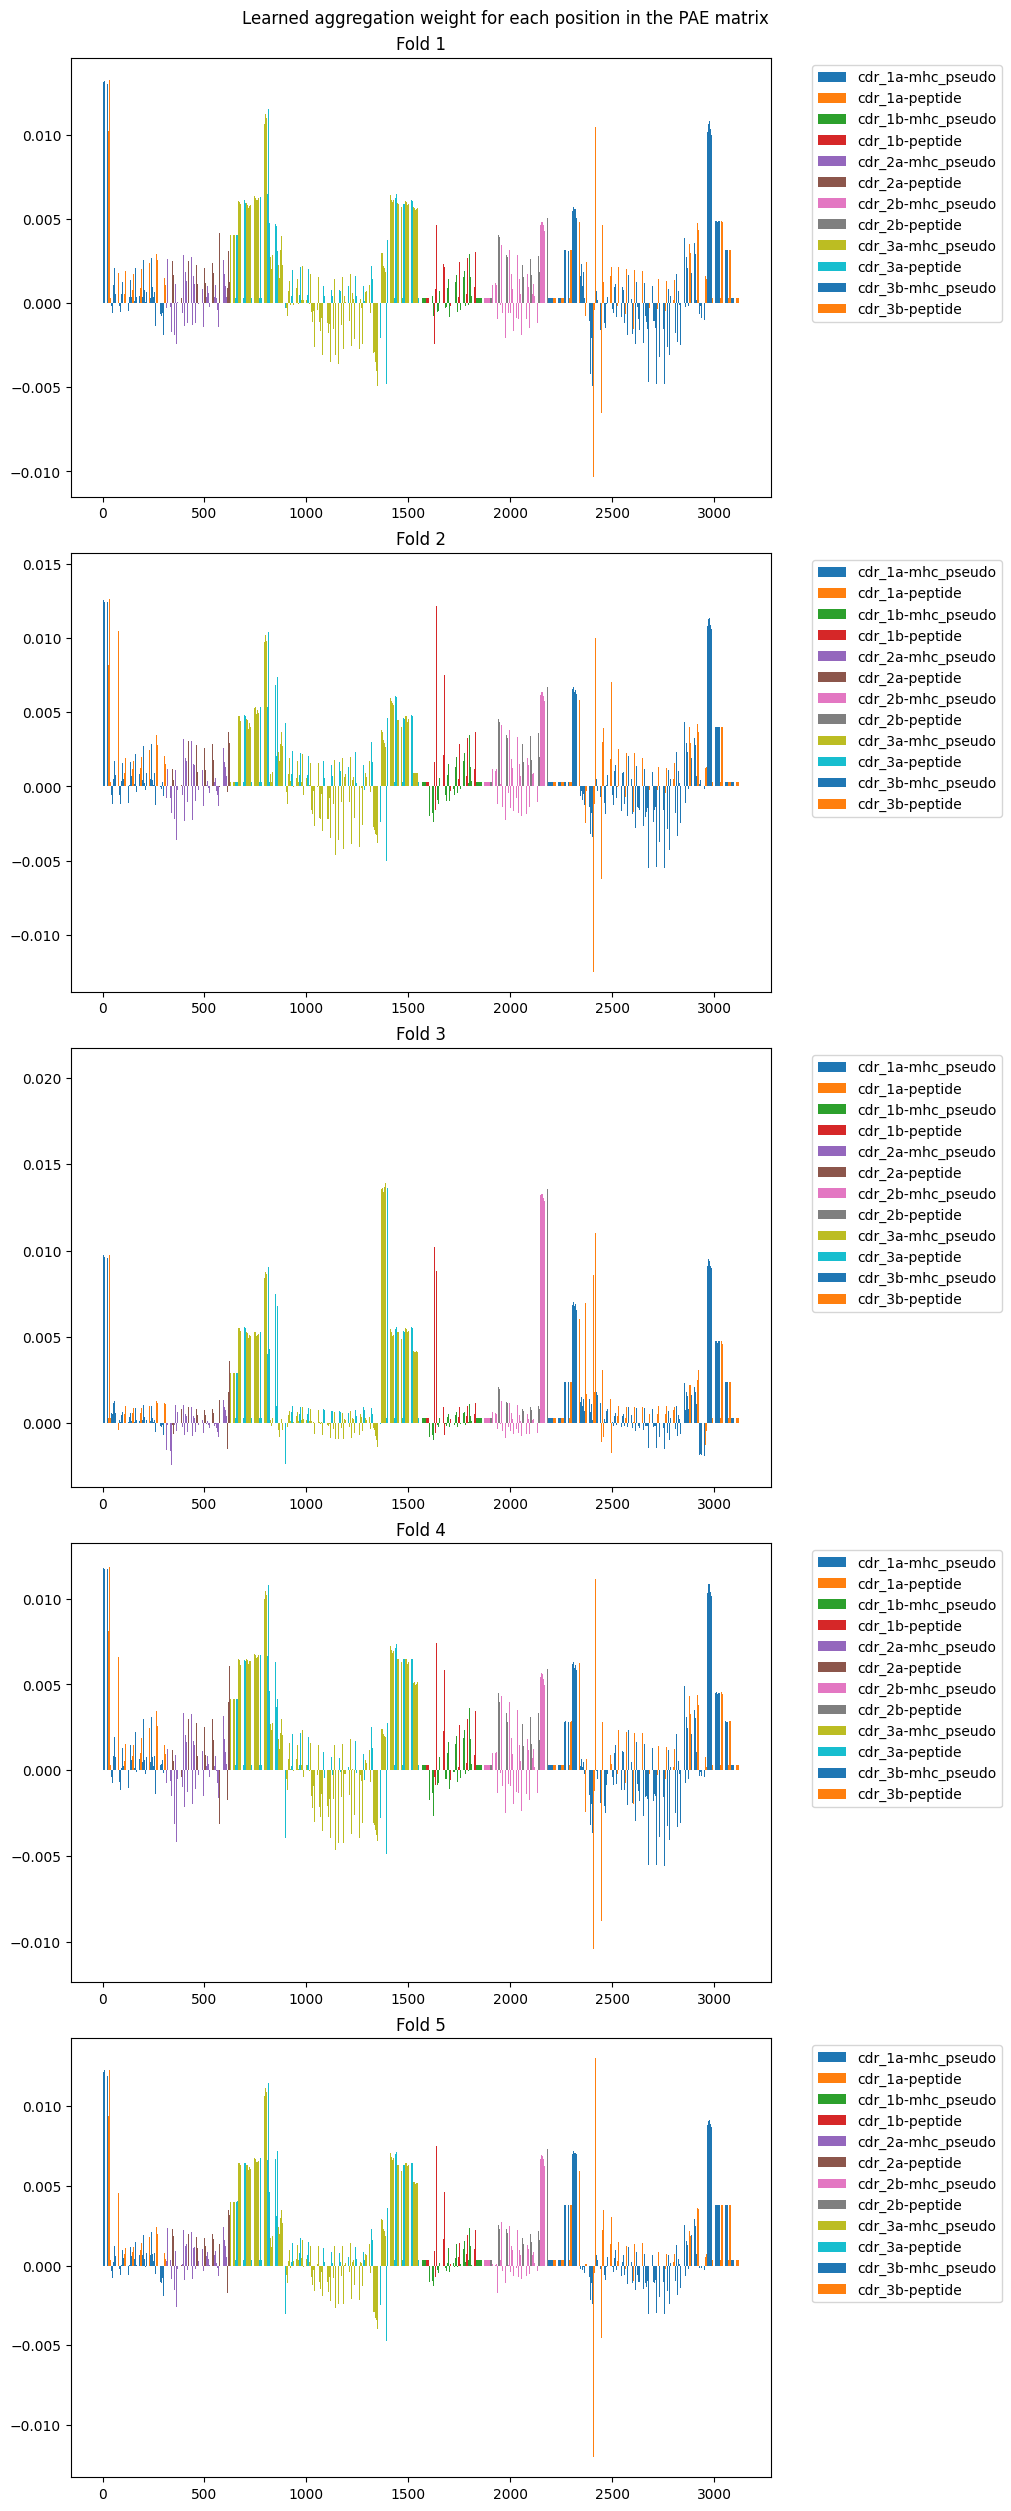

In [23]:
fig, axes = plt.subplots(num_folds, 1, figsize=(10, num_folds * 5), constrained_layout=True)

fig.suptitle('Learned aggregation weight for each position in the PAE matrix')

for i in range(num_folds):
    axes[i].set_title(f'Fold {i + 1}')
    axes[i].bar(range(1, weights[i].shape[0] + 1), weights[i], color=colours)

    handles = [Patch(facecolor=color, label=label) for label, color in label_to_colour.items()]
    axes[i].legend(handles=handles, bbox_to_anchor=(1.05, 1), loc='upper left')

plt.show()

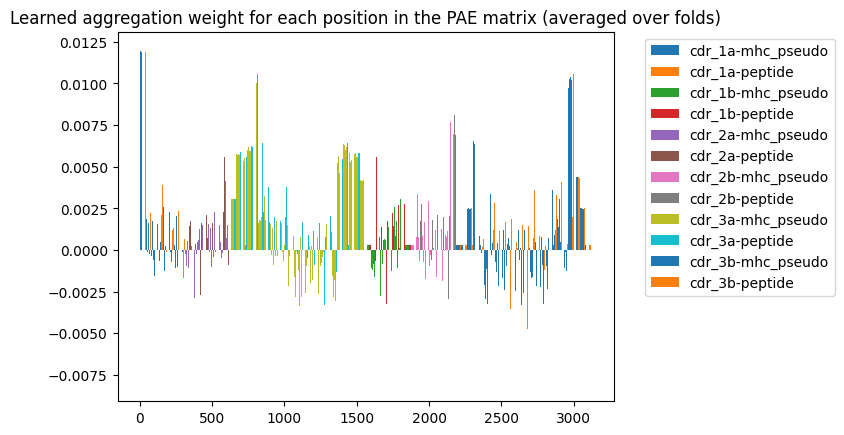

In [24]:
plt.title('Learned aggregation weight for each position in the PAE matrix (averaged over folds)')

plt.bar(range(1, weights.shape[-1] + 1), np.mean(weights, axis=0), color=colours)

handles = [Patch(facecolor=color, label=label) for label, color in label_to_colour.items()]
plt.legend(handles=handles, bbox_to_anchor=(1.05, 1), loc='upper left')

plt.show()

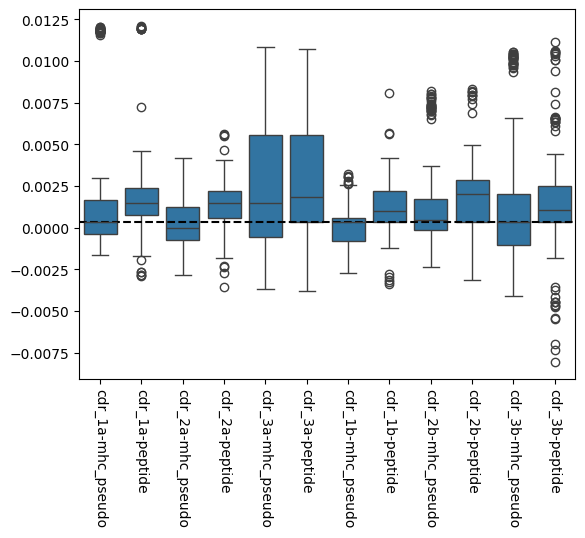

In [25]:
ax = sns.boxplot(x=labels, y=np.mean(weights, axis=0))

ax.axhline(1 / weights.shape[-1], color='black', linestyle='dashed')

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=270)

plt.show()

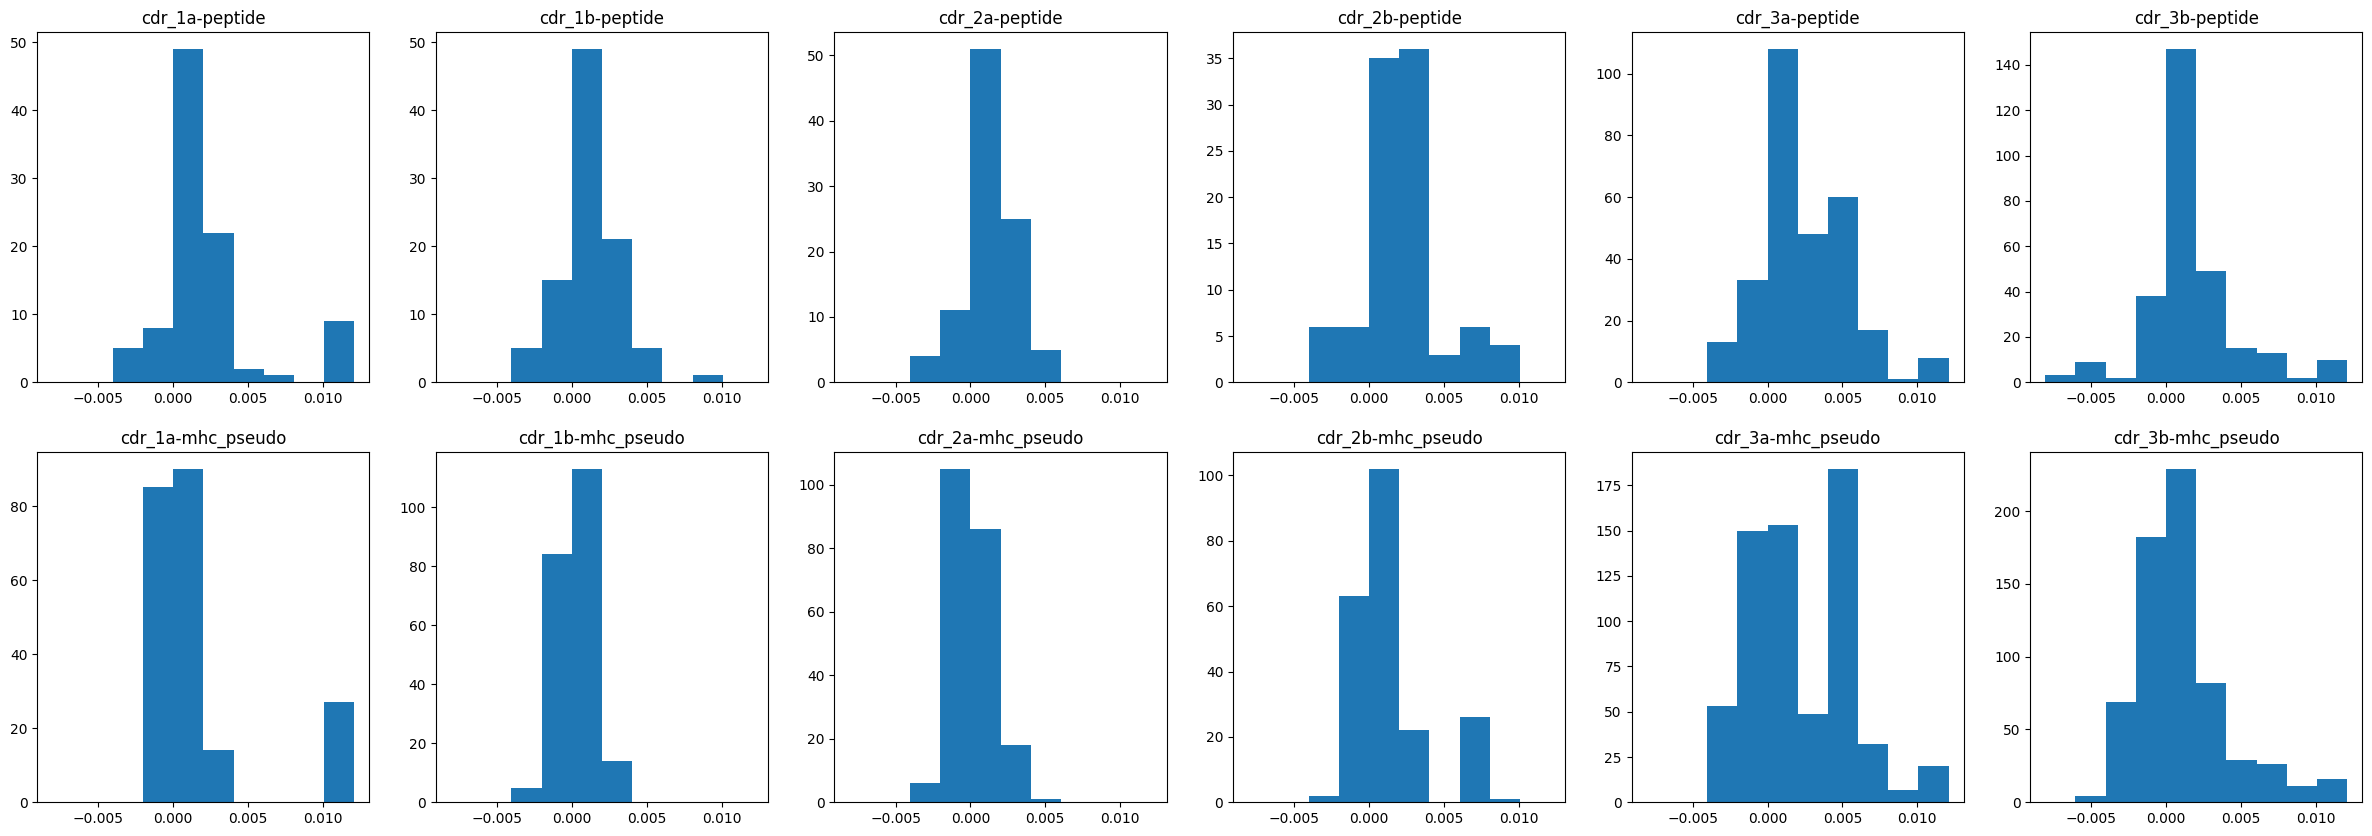

In [26]:
unique_labels = np.unique(labels)
fig, axes = plt.subplots(2, len(unique_labels) // 2, figsize=((len(unique_labels) // 2) * 5, 10))

weights_avg = np.mean(weights, axis=0)

x_min = np.min(weights_avg)
x_max = np.max(weights_avg)

for i, label in enumerate(unique_labels):
    row = 0 if 'peptide' in label else 1
    col = i // 2

    axes[row, col].set_title(label)
    axes[row, col].hist(weights_avg[labels == label], range=(x_min, x_max))

plt.show()

In [27]:
groups = [(label, weights_avg[labels == label]) for label in unique_labels]
print(stats.f_oneway(*[values for _, values in groups]))

print()

print('Post-hoc:')
print('                                          Stat        P-value    Significant?')

adj_alpha_level = 0.05 / len(groups)
for (label1, group1), (label2, group2) in itertools.combinations(groups, 2):
    stat, p_value = stats.ttest_ind(group1, group2)
    print(f'{label1: <17} - {label2: <20} {stat:6.2f}    {p_value:10.2e}    {p_value < adj_alpha_level}')

F_onewayResult(statistic=20.270017388292747, pvalue=4.168060958700108e-40)

Post-hoc:
                                          Stat        P-value    Significant?
cdr_1a-mhc_pseudo - cdr_1a-peptide        -1.19      2.34e-01    False
cdr_1a-mhc_pseudo - cdr_1b-mhc_pseudo      5.89      7.74e-09    True
cdr_1a-mhc_pseudo - cdr_1b-peptide         1.47      1.41e-01    False
cdr_1a-mhc_pseudo - cdr_2a-mhc_pseudo      5.42      9.88e-08    True
cdr_1a-mhc_pseudo - cdr_2a-peptide         0.80      4.25e-01    False
cdr_1a-mhc_pseudo - cdr_2b-mhc_pseudo      1.30      1.94e-01    False
cdr_1a-mhc_pseudo - cdr_2b-peptide        -0.92      3.58e-01    False
cdr_1a-mhc_pseudo - cdr_3a-mhc_pseudo     -1.79      7.38e-02    False
cdr_1a-mhc_pseudo - cdr_3a-peptide        -2.43      1.54e-02    False
cdr_1a-mhc_pseudo - cdr_3b-mhc_pseudo      3.60      3.34e-04    True
cdr_1a-mhc_pseudo - cdr_3b-peptide         0.71      4.77e-01    False
cdr_1a-peptide    - cdr_1b-mhc_pseudo      8.30      3.30e

## Comparison

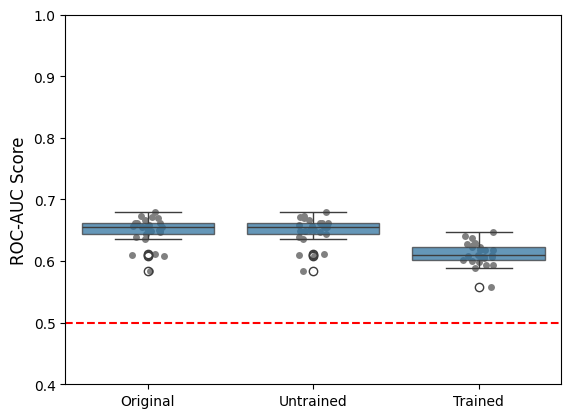

In [28]:
fig, ax = plt.subplots(1, 1)

sns.stripplot(
    data=[original_roc_auc_scores, untrained_roc_auc_scores, trained_roc_auc_scores], color='grey', ax=ax, zorder=1
)
sns.boxplot(
    data=[original_roc_auc_scores, untrained_roc_auc_scores, trained_roc_auc_scores],
    ax=ax,
    color='tab:blue',
    boxprops={'alpha': 0.75},
    zorder=2,
)

ax.axhline(0.5, color='red', linestyle='dashed')

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(['Original', 'Untrained', 'Trained'])

ax.set_ylim([0.4, 1.0])

ax.set_ylabel('ROC-AUC Score', fontsize=12)

plt.show()

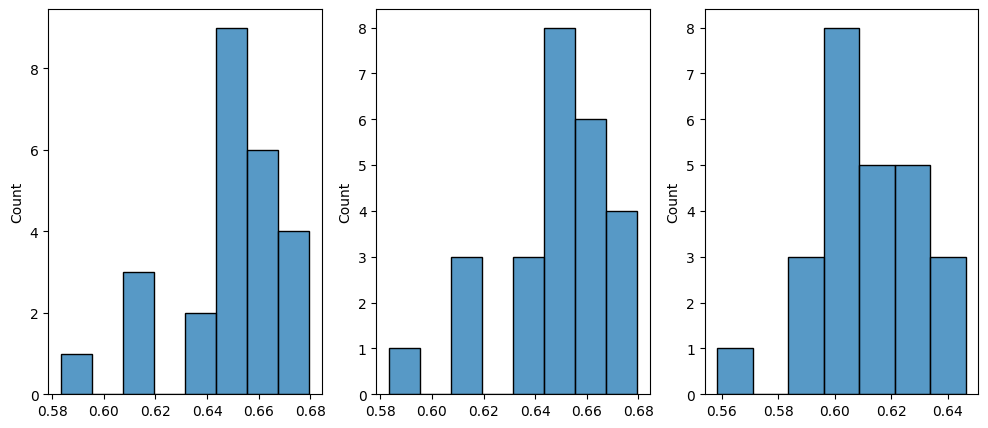

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for ax, roc_auc_scores in zip(
    axes, [original_roc_auc_scores, untrained_roc_auc_scores, trained_roc_auc_scores], strict=True
):
    sns.histplot(roc_auc_scores, ax=ax)

In [30]:
print(stats.kruskal(original_roc_auc_scores, untrained_roc_auc_scores, trained_roc_auc_scores))

combinations = list(
    itertools.combinations(
        (
            ('Original', original_roc_auc_scores),
            ('Untrained', untrained_roc_auc_scores),
            ('Trained', trained_roc_auc_scores),
        ),
        2,
    )
)

adj_alpha_level = SIGNIFICANCE_LEVEL / len(combinations)

print()
print('Post-hoc:')
for (label1, group1), (label2, group2) in combinations:
    stat, p_val = stats.ranksums(group1, group2)

    print(f'{label1: <15}{label2: <15}{stat: .2f}      {p_val: .2e}      significant? {p_val < adj_alpha_level}')

KruskalResult(statistic=30.45344371897181, pvalue=2.4384773106054515e-07)

Post-hoc:
Original       Untrained      -0.04       9.69e-01      significant? False
Original       Trained         4.76       1.90e-06      significant? True
Untrained      Trained         4.76       1.90e-06      significant? True
